# Process the frontier training and validation records

**Question:** What do the saved training and validation records support, and where does inference stop?

**Level:** A worked method and evidence analysis with an explicit claim boundary.

## Objectives

This lesson reads the committed, path-sanitized summary of the five-member training run and all 200 rows from its validation-only replay. It verifies the split identity and source commit, recomputes completion, objective, and coverage summaries, inspects member checkpoint-selection histories, and plots case-level results beside their limits. The records preserve genuine outputs from the product pipeline without model weights or machine-specific paths. This is an evidence-processing lesson: it does not retrain the actor, recreate lost test outputs, or score any product case.

## Setup

Use the pinned NumPy and Matplotlib packages from the repository notebook environment. The records and frozen split manifest are committed under the learned-frontier design folder, so this lesson runs from a fresh clone without access to the original training disk. Do not replace a missing record with copied values or a later run. Its JSON schema, digest fields, and source commit are part of provenance. A failed integrity check is a stop condition because untracked substitutions would make the displayed result impossible to audit.

Environment install command:

```bash
python -m pip install oreblocks==0.6.6 numpy==2.5.1 matplotlib==3.11.2
```

In [1]:
# Load committed provenance records and product split functions.
import hashlib
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import sys

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "data-pipeline").is_dir())
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.frontier_splits import build_split_manifest, manifest_sha256
from pipeline.model.frontier_policy import validate_split_manifest

RECORDS = ROOT / "docs/design/features/learned-frontier/records"
summary = json.loads((RECORDS / "training-summary.json").read_text(encoding="utf-8"))
diagnostic = json.loads((RECORDS / "validation-diagnostic.json").read_text(encoding="utf-8"))
manifest = json.loads(
    (ROOT / "docs/design/features/learned-frontier/split-manifest.json").read_text(encoding="utf-8")
)["manifest"]
from pipeline.model.frontier_data import generate_graph, FEATURE_NAMES
from pipeline.model.frontier_policy import (
    FeatureNormalizer,
    feasible_frontier,
    precedence_frontier,
    replay_frontier_policy,
    validate_schedule,
)
import importlib.metadata

print({name: importlib.metadata.version(name) for name in ("oreblocks", "numpy", "matplotlib")})


{'oreblocks': '0.6.6', 'numpy': '2.5.1', 'matplotlib': '3.11.2'}


## Data

The training summary omits checkpoint locations but retains the original receipt's digest, source commit, engine version, five member seeds, selected and final checkpoint hashes, transition histories, and compute caps. The validation diagnostic stores one row per declared validation seed, with graph family, size, assignment count, normalized objective, two coverage fractions, and independent validation status. A frozen manifest lists train, validation, and test partitions separately. None of the test rows appears in the validation record, and the fourteen product-case scenarios are not opened here.

## Method

First reconstruct the split from the product's generator and validate its disjointness. Match every diagnostic seed to the manifest's validation rows and verify the generator family, size, and independent-check status. Then recompute the descriptive aggregates from per-case rows instead of trusting the summary headline. For each training member, retain its validation history and selected checkpoint digest; a completed training receipt does not by itself establish a useful policy. The case plots retain empty schedules and zero coverage, while the distribution plot exposes the long tail. No threshold converts these validation observations into a test claim.

Rebuild the frozen partitions and validate their disjointness.

In [2]:
# Rebuild and validate the exact split manifest before reading result rows.
case_ids = manifest["product_case_ids"]
rebuilt = build_split_manifest(case_ids)
validate_split_manifest(manifest)
assert manifest_sha256(rebuilt) == summary["split_sha256"] == diagnostic["split_sha256"]
assert summary["training_source_commit"] == diagnostic["training_source_commit"]
print(
    {
        "split_sha256": summary["split_sha256"],
        "source_commit": summary["training_source_commit"],
        "members": len(summary["members"]),
    }
)


{'split_sha256': '18860c8a361576ba924ec95fd5dfe9d58c8a37a3466a1c17bb9765ddfc81350c', 'source_commit': '4aa49f4e72b2563d652a5636f69c2c5a5582db00', 'members': 5}


Join every diagnostic case to its frozen seed and size.

In [3]:
# Match each validation record to its frozen seed, family, and graph size.
expected = {row["seed"]: row for row in manifest["validation"]}
rows = diagnostic["case_results"]
for row in rows:
    frozen = expected[row["seed"]]
assert diagnostic["all_schedules_independently_validated"]


Recompute the reported distributions from the case rows.

In [4]:
# Recompute distribution summaries from case rows, retaining empty schedules.
npv = np.asarray([row["normalized_npv"] for row in rows], dtype=float)
value_coverage = np.asarray([row["positive_value_coverage"] for row in rows], dtype=float)
assigned = np.asarray([row["assigned_blocks"] for row in rows], dtype=int)
computed = {
    "cases": len(rows),
    "nonempty_fraction": float(np.mean(assigned > 0)),
    "mean_assigned_blocks": float(assigned.mean()),
    "median_npv": float(np.median(npv)),
    "median_value_coverage": float(np.median(value_coverage)),
    "minimum_npv": float(np.min(npv)),
    "maximum_npv": float(np.max(npv)),
}
print(computed)


{'cases': 200, 'nonempty_fraction': 0.49, 'mean_assigned_blocks': 1.84, 'median_npv': 0.0, 'median_value_coverage': 0.0, 'minimum_npv': -0.0015200422109756784, 'maximum_npv': 0.052875241354758566}


Inspect checkpoint-selection histories as training records.

In [5]:
# Summarize validation histories without converting them into test evidence.
for member in summary["members"]:
    history = member["validation_history"]
print(
    [
        {
            "seed": member["seed"],
            "transitions": member["transitions"],
            "stop": member["stop_reason"],
            "events": len(member["validation_history"]),
        }
        for member in summary["members"]
    ]
)


[{'seed': 1103, 'transitions': 40960, 'stop': 'cpu-cap', 'events': 1}, {'seed': 2207, 'transitions': 45056, 'stop': 'cpu-cap', 'events': 2}, {'seed': 3301, 'transitions': 61440, 'stop': 'cpu-cap', 'events': 2}, {'seed': 4409, 'transitions': 53248, 'stop': 'cpu-cap', 'events': 2}, {'seed': 5519, 'transitions': 53248, 'stop': 'cpu-cap', 'events': 2}]


Regenerate one validation graph from its frozen seed; this checks its public input contract only.

In [6]:
# Regenerate one validation graph from its frozen seed; this checks its public input contract only.
sample = rows[0]
example = generate_graph(sample["seed"], sample["family"], sample["size"])
print(
    {
        "seed": sample["seed"],
        "family": example.family,
        "size": len(example.instance.values),
        "features": FEATURE_NAMES,
    }
)


{'seed': 200000, 'family': 'crosscut', 'size': 32, 'features': ('value_norm', 'tonnage_norm', 'plant_use_fraction', 'grade_norm', 'depth_fraction', 'predecessor_count', 'successor_count')}


Fit a small normalizer on training graphs only and retain its digest with the feature order.

In [7]:
# Fit a small normalizer on training graphs only and retain its digest with the feature order.
train_graphs = [generate_graph(row["seed"], row["family"], row["size"]) for row in manifest["train"][:8]]
train_matrix = np.vstack([graph.node_features for graph in train_graphs])
normalizer = FeatureNormalizer.fit(train_matrix, FEATURE_NAMES, declared_features=FEATURE_NAMES)
print({"training_rows": normalizer.train_rows, "normalizer_sha256": normalizer.sha256})


{'training_rows': 368, 'normalizer_sha256': 'd4aab3f7fd25827c85fe0841c36bff0e7a2c4a6bda2a3ae82407d61828ba247d'}


Inspect an empty decision state without scoring the saved validation outcomes.

In [8]:
# Inspect an empty decision state without scoring the saved validation outcomes.
ready = precedence_frontier(example.instance, (), 0)
feasible = feasible_frontier(example.instance, (), 0)
print({"ready": len(ready), "feasible": len(feasible), "subset": set(feasible).issubset(ready)})


{'ready': 1, 'feasible': 1, 'subset': True}


Run a transparent mechanics replay and validate it independently; this is not a validation-record result.

In [9]:
# Run a transparent mechanics replay and validate it independently; this is not a validation-record result.
score = lambda block, period, assigned: float(example.instance.values[block]) if block >= 0 else -1.0
mechanics_result = replay_frontier_policy(example.instance, score, tonnage=example.tonnage)
print(
    {
        "assignments": len(mechanics_result.assignments),
        "validated_npv": validate_schedule(example.instance, mechanics_result.assignments),
    }
)


{'assignments': 2, 'validated_npv': 0.9884496550171686}


## Comparison

The saved training history and the later validation replay answer different questions. Validation events selected checkpoints, so inspecting those values is part of model selection. The post-selection replay checks surviving policies against the same validation partition and its independent schedule validator. Agreement between the two views is useful for debugging but does not create an independent sample. The lost one-shot synthetic test has no retained case results; its split-wide ledger prohibits repeating it. Product cases remain unopened. We therefore compare records and evidence states, not competing policy performance.

## Evidence

The first figure plots every validation case and keeps zero-assignment plans visible. The second summarizes schedule completion and coverage on the reused split. A complete validator pass means each returned schedule satisfies the declared constraints; it does not mean the schedule is operationally complete. A zero median value-coverage fraction and sparse assignments diagnose the current method's usefulness problem. Because checkpoints were selected on these same cases, these statistics remain descriptive and post-selection. They cannot justify superiority, generalization, or a user-facing schedule selector.

The record deliberately retains each seed and graph size rather than distributing only an aggregate table. This permits a reader to audit joins, reproduce quantiles, inspect outliers, and detect a missing row without guessing how the summary was made. Hashes bind the public summary to its external original receipt and frozen split. The public diagnostic is therefore sufficient for its stated descriptive calculations, while the private checkpoint files remain unnecessary for reproducing those calculations.

The summary intentionally does not include the state-action trajectories or trained weights. A reader can verify record membership, recalculate the published descriptive values, and inspect case variation, but cannot reconstruct the policy's choices from this compact record alone. That distinction is important for reproducibility: the lesson reproduces the analysis of the surviving record, not a lost evaluation. The split ledger also makes clear that replaying validation again would repeat model-selection data rather than create fresh evidence.

Plot every validation case, including empty schedules.

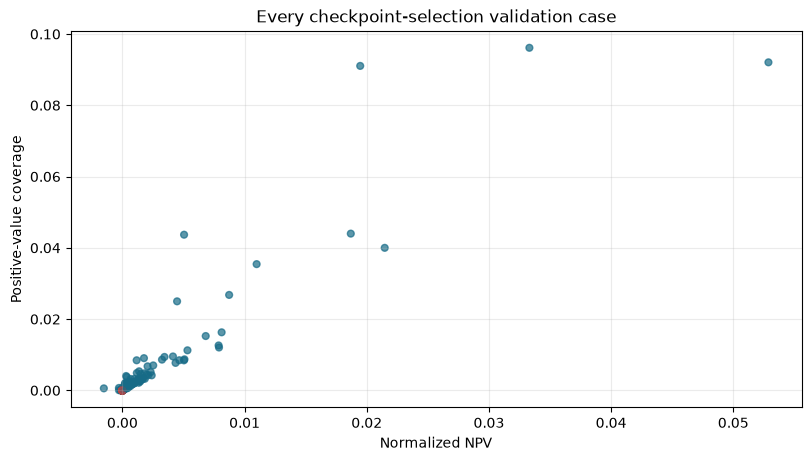

In [10]:
# Plot every case and identify zero-coverage outcomes directly.
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.scatter(npv, value_coverage, c=np.where(assigned > 0, "#176B87", "#B84444"), alpha=0.7, s=24)
ax.set(
    xlabel="Normalized NPV",
    ylabel="Positive-value coverage",
    title="Every checkpoint-selection validation case",
)
ax.grid(alpha=0.25)
plt.show()


The plotted points are the original per-case rows. Their visible spread matters because a central statistic hides empty schedules and negative outcomes. Red points mark cases with no assigned block, while the vertical position retains positive-value coverage. This joint view exposes where a feasible schedule still leaves value untouched.

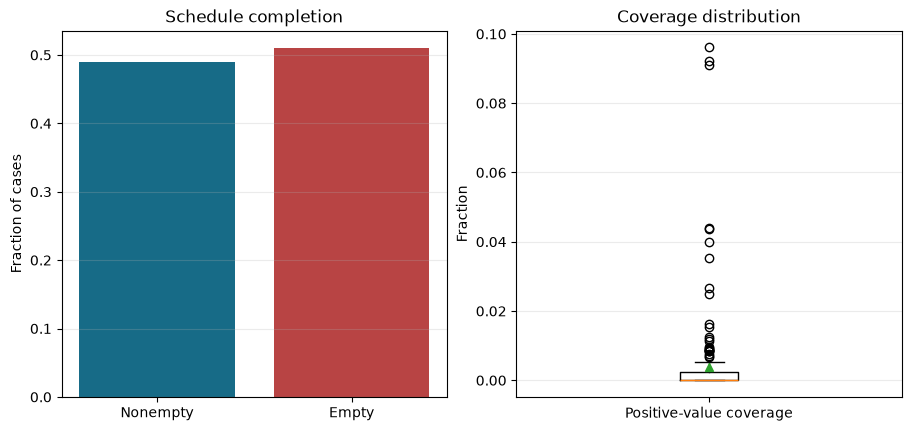

In [11]:
# Plot completion and value coverage beside their full observed range.
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), constrained_layout=True)
axes[0].bar(
    ["Nonempty", "Empty"], [np.mean(assigned > 0), np.mean(assigned == 0)], color=["#176B87", "#B84444"]
)
axes[0].set(ylabel="Fraction of cases", title="Schedule completion")
axes[1].boxplot([value_coverage], tick_labels=["Positive-value coverage"], showmeans=True)
axes[1].set(ylabel="Fraction", title="Coverage distribution")
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
plt.show()


## Results

Read the mean beside the median, range, nonempty fraction, assigned blocks, and both forms of coverage. A small positive mean can coexist with a median of zero when most runs return no value-bearing blocks and a few cases carry the aggregate. The member histories also show the finite training budget and actual validation checkpoints. Neither a saved checkpoint hash nor a finite loss curve is an acceptance criterion for a mining schedule. Missing held-out outcomes remain unavailable rather than being reconstructed from model behavior or replaced by validation rows.

**Answer:** The 200 validation records supports the stated calculations, with its validation-only status limiting the conclusion.

## Summary

The record processing is reproducible and the negative evidence is preserved. The current outputs support statements about capped training completion, checkpoint provenance, independently validated schedules on the reused validation set, and sparse case coverage. They do not support a held-out performance result. Recovery requires a reviewed versioned protocol, a new disjoint seed-and-family split, and persisted per-case outputs before any product cases are opened. Use the current notebook to explain that boundary and audit the diagnostics; do not present it as a final benchmark or a deployment artifact.

## References

The SDD and run records are maintained in the PhaseFlow repository. The clipped policy-gradient paper describes the optimizer family but does not support empirical claims for this mine-scheduling policy. All displayed counts, distributions, and summaries are recomputed from the committed JSON records.

- Proximal policy optimization: https://arxiv.org/abs/1707.06347
- PhaseFlow implementation and records: https://github.com/fsantibanezleal/CAOS_PhaseFlow